<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/02_Workflows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import torch
import numpy as np
from torch import nn
import seaborn as sns

In [33]:
torch.manual_seed(10)
x=np.linspace(0,20,num=200)
y=x+np.sin(x)*2+np.random.normal(size=x.shape)

In [34]:
x.shape,y.shape

((200,), (200,))

<Axes: >

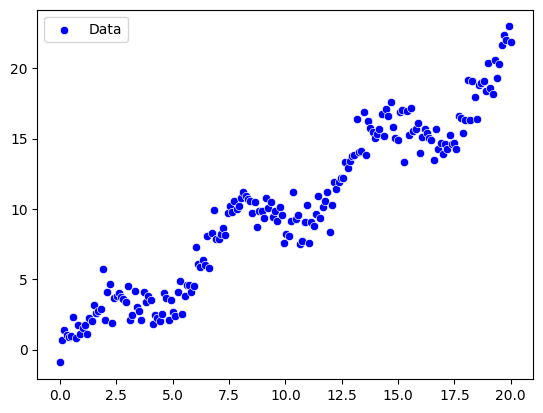

In [35]:
sns.scatterplot(x=x,y=y,color='blue',label='Data')

In [36]:
from torch.utils.data import Dataset,DataLoader
class simple1DRegressionDataset(Dataset):
  def __init__(self,x,y):
    super().__init__()
    self.x=x.reshape(-1,1)
    self.y=y.reshape(-1,1)
  def __getitem__(self, index):
    return torch.tensor(self.x[index,:],dtype=torch.float32),torch.tensor(self.y[index,:],dtype=torch.float32)
  def __len__(self):
    return self.x.shape[0]


In [37]:
df=simple1DRegressionDataset(x,y)

In [38]:
df[0]

(tensor([0.]), tensor([-0.9169]))

In [39]:
trainig_loader=DataLoader(simple1DRegressionDataset(x,y),shuffle=True)
data_point=next(iter(trainig_loader))

In [40]:
in_feutures=1
out_feutures=1
model_2=nn.Linear(in_features=in_feutures,out_features=out_feutures)

In [41]:
loss_fn=nn.MSELoss()

In [42]:
optimizier=torch.optim.SGD(params=model_2.parameters(),lr=0.001)

In [43]:
from tqdm.autonotebook import tqdm
def train_simple_network(model=model_2,
                         device='cpu',
                         epochs=5,
                         trainig_loader=trainig_loader,
                         loss_fn=loss_fn,
                         optimizier=optimizier):
  optimizier=torch.optim.SGD(params=model_2.parameters(),lr=0.001)
  model.to(device)
  for epoch in tqdm(range(epochs),desc='epochs'):
    model.train()
    runing_train=0
    for inputs,labels in tqdm(trainig_loader,desc='Batches'):
      inputs=inputs.to(device)
      labels=labels.to(device)
      y_pred=model(inputs)
      loss=loss_fn(y_pred,labels)
      loss.backward()
      optimizier.zero_grad()
      runing_train+=loss.item()


In [44]:
device='cuda' if torch.cuda.is_available() else 'cpua'
device

'cuda'

In [51]:
train_simple_network(model=model_2,
                    device =device,
                    epochs=10,
                    trainig_loader=trainig_loader,
                    loss_fn=loss_fn)


epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]